# 02. Entrenamiento: baseline con validación temporal

**Etapa 2 del proyecto MLE III.** Establecemos una referencia reproducible antes de optimizar. Se comparan un predictor trivial y un árbol de decisión con configuración fijada de antemano.

Solo se utilizan los steps **1–250**. Los bloques de ajuste del umbral, prueba offline y producción permanecen reservados. Este notebook no presenta todavía un champion ni los resultados de Random Search/Optuna.

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
import joblib
from IPython.display import display, Markdown, Image

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'src/fraud/baseline.py').is_file())
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
from src.fraud.baseline import run_baseline, TREE_PARAMS
from src.fraud.prepare import sha256
from src.fraud.schema import FEATURES
from src.fraud.tracking import configure

REPORTS = ROOT/'reports/baseline'
if not (REPORTS/'summary.json').exists():
    run_baseline(ROOT)
summary = json.loads((REPORTS/'summary.json').read_text(encoding='utf-8'))
assert summary['tree_parameters'] == TREE_PARAMS
assert sha256(ROOT/'artifacts/baseline/pipeline_baseline.joblib') == summary['model_sha256']
assert not any(summary[k] for k in ['threshold_partition_used','offline_test_used','production_used'])
print('Filas de desarrollo:', summary['development_rows'])
print('Filas de validación fuera de muestra:', summary['oof_rows'])

Filas de desarrollo: 3248292
Filas de validación fuera de muestra: 2188776


## 1. Modelos y protocolo

- **DummyClassifier(strategy="prior")**: aprende la prevalencia de entrenamiento y asigna el mismo score a todas las transacciones. Con umbral 0,5 no emite alertas en este problema desbalanceado.
- **DecisionTreeClassifier**: profundidad máxima 6, mínimo 20 filas por hoja, pesos balanceados y semilla 42. Estos valores son un baseline fijado, no el resultado de una búsqueda.
- Imputación por mediana con indicador de nulos y one-hot de tipo dentro de cada pipeline. La lista de tipos procede del contrato del dataset. No se balancea ni se reduce la población de validación.
- Umbral fijo **0,5** para comparar decisiones. Se ajustará después, utilizando únicamente su partición reservada.
- El árbol ponderado produce scores útiles para ordenar; **no afirmamos que sean probabilidades calibradas**.

In [2]:
display(pd.DataFrame([TREE_PARAMS]))
folds = pd.read_csv(ROOT/'reports/temporal_folds.csv')
display(folds)

,max_depth,min_samples_leaf,class_weight,random_state
0,6,20,balanced,42


,fold,train_steps,validation_steps,train_rows,validation_rows,train_frauds,validation_frauds
0,1,1–100,101–150,1059516,451852,1190,520
1,2,1–150,151–200,1511368,870814,1710,544
2,3,1–200,201–250,2382182,866110,2254,587


## 2. Resultados por ventana

Average Precision (AP) resume la curva precision-recall y no es el área trapezoidal de esa curva. ROC-AUC evalúa ordenamiento; precision y recall dependen del umbral. Cuando no hay alertas se reporta precision=0 con la convención zero_division=0, indicando explícitamente la ausencia de alertas.

La tabla muestra métricas de validación temporal. No son métricas de entrenamiento ni de la prueba offline.

In [3]:
fold_metrics = pd.read_csv(REPORTS/'fold_metrics.csv')
display(fold_metrics[['model','fold','validation_rows','average_precision','roc_auc','precision','recall','f2','alert_rate','fp','fn','fit_seconds']])
comparison = pd.read_csv(REPORTS/'comparison.csv')
display(comparison[['model','average_precision_mean','average_precision_std','precision_mean','recall_mean','f2_mean','fit_seconds_mean']])

,model,fold,validation_rows,average_precision,roc_auc,precision,recall,f2,alert_rate,fp,fn,fit_seconds
0,dummy_prior,1,451852,0.001151,0.500000,0.000000,0.000000,0.000000,0.000000,0,520,3.776328
1,dummy_prior,2,870814,0.000625,0.500000,0.000000,0.000000,0.000000,0.000000,0,544,5.865011
2,dummy_prior,3,866110,0.000678,0.500000,0.000000,0.000000,0.000000,0.000000,0,587,9.849673
3,decision_tree,1,451852,1.000000,1.000000,0.777280,1.000000,0.945798,0.001481,149,0,18.500130
4,decision_tree,2,870814,0.989931,0.999698,0.536561,0.998162,0.851631,0.001162,469,1,24.399303
5,decision_tree,3,866110,0.992911,0.996862,0.832857,0.993186,0.956365,0.000808,117,4,48.591626


,model,average_precision_mean,average_precision_std,precision_mean,recall_mean,f2_mean,fit_seconds_mean
0,decision_tree,0.994281,0.005172,0.715566,0.997116,0.917931,30.497020
1,dummy_prior,0.000818,0.000290,0.000000,0.000000,0.000000,6.497004


Las medias y desviaciones son entre tres ventanas, con tamaños distintos. La desviación no es un intervalo de confianza y tampoco demuestra ausencia de sobreajuste.

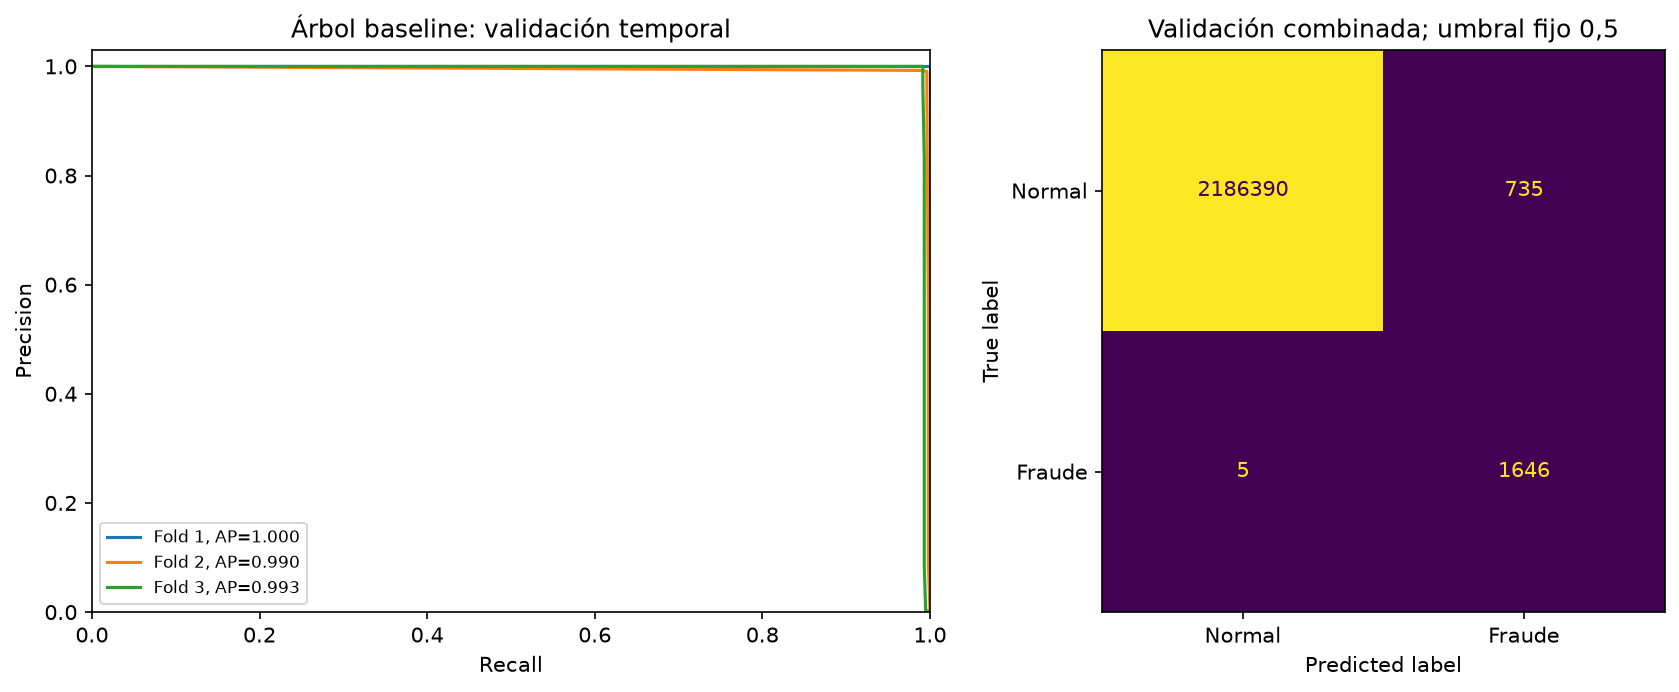

,average_precision,roc_auc,precision,recall,f1,f2,alert_rate,prevalence,tn,fp,fn,tp
0,0.994248,0.998709,0.691306,0.996972,0.816468,0.915971,0.001088,0.000754,2186390,735,5,1646


In [4]:
display(Image(filename=str(REPORTS/'baseline_validation.png')))
display(pd.DataFrame([summary['tree_pooled_validation']]))

La matriz combina predicciones del árbol sobre ventanas de validación disjuntas, con modelos entrenados en periodos anteriores. Es una evaluación temporal fuera de muestra dentro de desarrollo; no sustituye la prueba offline reservada.

## 3. Auditoría de resultados altos

El dataset es una simulación y utilizamos saldos finales y discrepancias contables bajo un contrato posterior a transacción. Esas relaciones pueden hacer muy separables los fraudes. Un resultado alto no se traslada automáticamente a prevención en tiempo real ni a datos bancarios reales.

Controles implementados: target y alerta excluidos de X; IDs y step rechazados como predictores; validación estrictamente posterior al entrenamiento; horas completas; transformadores ajustados en training; conservación de la prevalencia en validación.

In [5]:
forbidden = {'isFraud','isFlaggedFraud','nameOrig','nameDest','step','row_id'}
assert not set(FEATURES).intersection(forbidden)
assert (fold_metrics.train_max_step < fold_metrics.validation_min_step).all()
assert (fold_metrics.validation_max_step <= 250).all()
pipeline = joblib.load(ROOT/'artifacts/baseline/pipeline_baseline.joblib')
assert set(pipeline.named_steps['contract'].feature_names_in_) == set(FEATURES)
print('Controles de predictores y temporalidad verificados.')
rules_path = REPORTS/'tree_rules.txt'
if rules_path.exists():
    print(rules_path.read_text(encoding='utf-8'))

Controles de predictores y temporalidad verificados.
|--- numeric__origin_debit_discrepancy <= -0.005000
|   |--- numeric__destination_credit_discrepancy <= -1342986.500000
|   |   |--- numeric__oldbalanceDest <= 5261.000000
|   |   |   |--- class: 1
|   |   |--- numeric__oldbalanceDest >  5261.000000
|   |   |   |--- class: 0
|   |--- numeric__destination_credit_discrepancy >  -1342986.500000
|   |   |--- numeric__destination_balance_change <= 9291503.000000
|   |   |   |--- numeric__destination_balance_change <= 23292.250000
|   |   |   |   |--- numeric__origin_balance_change <= 79444.226562
|   |   |   |   |   |--- class: 0
|   |   |   |   |--- numeric__origin_balance_change >  79444.226562
|   |   |   |   |   |--- numeric__origin_balance_change <= 79844.500000
|   |   |   |   |   |   |--- class: 1
|   |   |   |   |   |--- numeric__origin_balance_change >  79844.500000
|   |   |   |   |   |   |--- class: 0
|   |   |   |--- numeric__destination_balance_change >  23292.250000
|   |   

El árbol guardado se ajustó sobre todo development (1–250). Sus reglas ayudan a inspeccionar qué relaciones utiliza, pero las métricas mostradas corresponden a los modelos de cada fold, no a evaluar ese refit sobre su entrenamiento.

## 4. Tracking y modelo reproducible

MLflow conserva el run de comparación, seis runs hijos (dos modelos por tres folds), parámetros, métricas y un modelo sklearn con firma y dependencias. El baseline no se registra como modelo productivo.

In [6]:
mlflow, experiment_id, backend, experiment_name = configure(ROOT, experiment_name='fraud-baseline-temporal', backend='local')
client = mlflow.MlflowClient()
run = client.get_run(summary['run_id'])
assert run.info.status == 'FINISHED'
model_artifacts = [a.path for a in client.list_artifacts(summary['run_id'], 'model')]
assert 'model/MLmodel' in model_artifacts and 'model/model.pkl' in model_artifacts
display({'local_run_id': run.info.run_id, 'status': run.info.status, 'model_reload_verified': summary['model_reload_verified']})
remote_path = REPORTS/'remote_tracking.json'
if remote_path.exists():
    remote = json.loads(remote_path.read_text(encoding='utf-8'))
    display(Markdown(f"[Run verificado en DagsHub]({remote['run_url']})"))
    display({k: remote[k] for k in ['remote_write_verified','run_status','model_artifacts_verified','model_role']})
else:
    print('Publicación remota pendiente; el resultado local está disponible.')

{'local_run_id': 'fde5ae49c22248ffa6da2c03922729e7',
 'status': 'FINISHED',
 'model_reload_verified': True}

Publicación remota pendiente; el resultado local está disponible.


## 5. Decisiones para la siguiente etapa

1. Mantener el baseline como referencia y comparar Random Search con Optuna/TPE sobre una misma familia de boosting.
2. Usar las mismas ventanas y un presupuesto comparable; registrar AP y tiempo. La búsqueda no tiene garantizado superar al baseline.
3. No ajustar el umbral sobre estas métricas ni abrir repetidamente el test offline para decidir configuraciones.
4. Investigar la utilidad de cada grupo de features y documentar la dependencia de saldos finales. Los resultados no prueban causalidad ni generalización a fraude real.
5. Tras seleccionar configuración: usar steps 251–300 para umbral y 301–400 para la evaluación offline final; después reproducir producción para monitoreo.

El notebook se ampliará con optimización en la etapa 3. Fuentes: material de sesiones 1, 3 y 4; contrato del notebook 1; documentación de [DecisionTreeClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html) y [MLflow sklearn](https://mlflow.org/docs/latest/api_reference/python_api/mlflow.sklearn.html).